# *E. coli* MIC and molecular properties

DSA103 — Session 12: Life Science Dataset  
ChEMBL activity data (target CHEMBL354) are combined with PubChem molecular descriptors to explore whether molecular properties relate to antibacterial activity. Lower MIC indicates stronger activity.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white", rc={"figure.figsize": (10, 6)})
pd.set_option("display.max_rows", 30)
pd.set_option("display.max_columns", 25)


from IPython.display import HTML, display

def display_df(**dataframes):
    html = "<div style='display: flex; gap: 16px; align-items: flex-start; overflow-x: auto;'>"
    
    for name, df in dataframes.items():
        html += f"""
        <div style='flex: 0 0 auto;'>
            <h4 style='margin-top: 0;'>{name}</h4>
            <div style='height: 250px; overflow: auto;'>
                {df.to_html()}
            </div>
        </div>
        """
    
    html += "</div>"
    display(HTML(html))

## ChEMBL data

The exported MIC data are restricted to molecules between 200 and 400 g/mol. Entries without SMILES are removed because their molecular descriptors cannot be retrieved from PubChem.

In [2]:
DATA_DIR = Path.cwd() / "chembl"
csv_path = next(DATA_DIR.glob("*.csv"))

df_full = pd.read_csv(csv_path, delimiter=";", low_memory=False)

# Restrict molecular weight to 200–400 g/mol
df_full["Molecular Weight"] = pd.to_numeric(
    df_full["Molecular Weight"], errors="coerce"
)

df_full = df_full[
    df_full["Molecular Weight"].between(200, 400)
].copy()

columns = [
    "Molecule ChEMBL ID",
    "Smiles",
    "Standard Type",
    "Standard Relation",
    "Standard Value",
    "Standard Units",
    "Assay ChEMBL ID"
]

df = df_full[columns].copy()

# Remove molecules without SMILES, as they cannot be used for descriptor calculations
df = df.dropna(subset=["Smiles"])

# Rename columns for easier handling
df.columns = [
    "chembl_id",
    "smiles",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "assay_id"
]

display_df(df=df.head(20))
print(f"Remaining entries: {len(df):,}")

,chembl_id,smiles,standard_type,standard_relation,standard_value,standard_units,assay_id
0,CHEMBL315498,Cc1cc(-c2cc3c(cc2F)c(=O)c(C(=O)O)cn3C2CC2)cc(C)n1,MIC,'=',0.030,ug.mL-1,CHEMBL678958
1,CHEMBL148,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(SCCNC=N)C[C@H]12,MIC,'=',0.250,ug.mL-1,CHEMBL1691760
8,CHEMBL148,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(SCCNC=N)C[C@H]12,MIC,'=',16.000,ug.mL-1,CHEMBL1696921
13,CHEMBL2314968,N/N=C1/c2cc(Br)ccc2-n2c1nc1ccccc1c2=O,MIC,'>',100.000,ug.mL-1,CHEMBL3863768
15,CHEMBL3950241,O=c1c2ccccc2nc2n1-c1ccccc1/C2=N/N=C1/C=C(O)CCC1,MIC,'=',6.250,ug.mL-1,CHEMBL3863768
21,CHEMBL1644459,C[n+]1nn(C2CCNCC2)c2c1C(=O)c1ccccc1C2=O.[Cl-],MIC,'=',32.000,ug.mL-1,CHEMBL1647491
23,CHEMBL138896,Cc1c(N2CCCC(C)(C)C2)c(N)cc2c(=O)c(C(=O)O)cn(C3CC3)c12,MIC,'=',0.500,ug.mL-1,CHEMBL676416
27,CHEMBL9,CCn1cc(C(=O)O)c(=O)c2cc(F)c(N3CCNCC3)cc21,MIC,'=',0.194,ug.mL-1,CHEMBL1634866
28,CHEMBL9,CCn1cc(C(=O)O)c(=O)c2cc(F)c(N3CCNCC3)cc21,MIC,'=',0.023,ug.mL-1,CHEMBL1634867
31,CHEMBL130,O=C(N[C@H](CO)[C@H](O)c1ccc([N+](=O)[O-])cc1)C(Cl)Cl,MIC,NaN,NaN,NaN,CHEMBL1661370


Remaining entries: 32,504


In [3]:
df_sample = df.sample(n=300, random_state=42)

OUTPUT_DIR = Path.cwd() / "output"
OUTPUT_DIR.mkdir(exist_ok=True)

df_sample.to_csv(OUTPUT_DIR / "chembl_sample.csv", index=False)

display_df(sample=df_sample)

,chembl_id,smiles,standard_type,standard_relation,standard_value,standard_units,assay_id
64661,CHEMBL5565601,CCCNC(=O)NCCc1c[nH]c2ccccc12,MIC,'=',4.000000e+00,ug.mL-1,CHEMBL5524297
29491,CHEMBL549605,O=C(c1ccccc1Br)n1ccnc1-c1ccc([N+](=O)[O-])cc1,MIC,'=',4.000000e+00,10'-3micromol/ml,CHEMBL1031924
13230,CHEMBL3596978,COC(=O)c1c(/C=C/c2ccccc2)cc(OC)c(CC=C(C)C)c1O,MIC,'>',1.280000e+02,ug.mL-1,CHEMBL3598766
20659,CHEMBL81662,CNC[C@H](O)C[C@@H](N)CC(=O)NN(C)CC(=O)O,MIC,'=',1.600000e+01,ug.mL-1,CHEMBL682950
48501,CHEMBL4225647,Cc1ccc(COc2ccc3cc(C4N=C(N)NC(N(C)C)=N4)ccc3c2)cc1,MIC,'=',2.000000e+00,ug.mL-1,CHEMBL4222879
53277,CHEMBL1814451,O=C1/C(=C/c2ccc(F)cc2)Oc2cc(O)cc(O)c21,MIC,'>',5.000000e+05,nM,CHEMBL4400790
5104,CHEMBL78110,O=C(c1ccc(Cl)cc1Cl)C(F)(Cn1ccnc1)c1ccccc1,MIC,'>',1.000000e+02,ug.mL-1,CHEMBL678382
35045,CHEMBL148,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(SCCNC=N)C[C@H]12,MIC,'=',1.200000e-01,ug.mL-1,CHEMBL1636075
13935,CHEMBL59899,O=C(COc1ccccc1)N[C@@H]1C(=O)N2C(C(=O)O)=CCS[C@H]12,MIC,'>',1.280000e+02,ug.mL-1,CHEMBL673753
60450,CHEMBL4566300,Cn1cnc(CN(CCCO)Cc2ncn(C)n2)n1,MIC,'=',7.000000e+00,ug.mL-1,CHEMBL4349312


## PubChem descriptors

A reproducible sample of 300 ChEMBL records is exported and processed with the supplied `pubchem_search.py` script. The script uses the paths in the project's `output` folder.

In [4]:
%run pubchem_search.py

100%|██████████| 300/300 [05:36<00:00,  1.12s/it]

Saved 300 entries.


In [5]:
df_pubchem = pd.read_csv(
    OUTPUT_DIR / "antibio_pubchem_descr.csv"
)

display_df(
    chembl=df_sample.head(10),
    pubchem=df_pubchem.head(10)
)

print(f"ChEMBL entries: {len(df_sample)}")
print(f"PubChem entries: {len(df_pubchem)}")

,chembl_id,smiles,standard_type,standard_relation,standard_value,standard_units,assay_id
64661,CHEMBL5565601,CCCNC(=O)NCCc1c[nH]c2ccccc12,MIC,'=',4.00,ug.mL-1,CHEMBL5524297
29491,CHEMBL549605,O=C(c1ccccc1Br)n1ccnc1-c1ccc([N+](=O)[O-])cc1,MIC,'=',4.00,10'-3micromol/ml,CHEMBL1031924
13230,CHEMBL3596978,COC(=O)c1c(/C=C/c2ccccc2)cc(OC)c(CC=C(C)C)c1O,MIC,'>',128.00,ug.mL-1,CHEMBL3598766
20659,CHEMBL81662,CNC[C@H](O)C[C@@H](N)CC(=O)NN(C)CC(=O)O,MIC,'=',16.00,ug.mL-1,CHEMBL682950
48501,CHEMBL4225647,Cc1ccc(COc2ccc3cc(C4N=C(N)NC(N(C)C)=N4)ccc3c2)cc1,MIC,'=',2.00,ug.mL-1,CHEMBL4222879
53277,CHEMBL1814451,O=C1/C(=C/c2ccc(F)cc2)Oc2cc(O)cc(O)c21,MIC,'>',500000.00,nM,CHEMBL4400790
5104,CHEMBL78110,O=C(c1ccc(Cl)cc1Cl)C(F)(Cn1ccnc1)c1ccccc1,MIC,'>',100.00,ug.mL-1,CHEMBL678382
35045,CHEMBL148,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(SCCNC=N)C[C@H]12,MIC,'=',0.12,ug.mL-1,CHEMBL1636075
13935,CHEMBL59899,O=C(COc1ccccc1)N[C@@H]1C(=O)N2C(C(=O)O)=CCS[C@H]12,MIC,'>',128.00,ug.mL-1,CHEMBL673753
60450,CHEMBL4566300,Cn1cnc(CN(CCCO)Cc2ncn(C)n2)n1,MIC,'=',7.00,ug.mL-1,CHEMBL4349312


ChEMBL entries: 300
PubChem entries: 300


## Combining the datasets

Repeated SMILES in the PubChem output are removed before merging. ChEMBL activity records are kept, since the same molecule may have been measured in different assays.

In [6]:
# Check for duplicate molecular descriptors
print("Duplicate SMILES in PubChem:",
      df_pubchem.duplicated(subset="smiles").sum())

df_pubchem = df_pubchem.drop_duplicates(subset="smiles")

# Merge ChEMBL activities with PubChem descriptors
df_merged = df_sample.merge(
    df_pubchem,
    on="smiles",
    how="inner",
    validate="many_to_one"
)

print(f"ChEMBL entries: {len(df_sample)}")
print(f"Merged entries: {len(df_merged)}")

display_df(
    merged=df_merged.head(10),
    missing=df_merged.isna().sum().to_frame("Missing values")
)

Duplicate SMILES in PubChem: 45
ChEMBL entries: 300
Merged entries: 300


,chembl_id,smiles,standard_type,standard_relation,standard_value,standard_units,assay_id,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,HeavyAtomCount
0,CHEMBL5565601,CCCNC(=O)NCCc1c[nH]c2ccccc12,MIC,'=',4.00,ug.mL-1,CHEMBL5524297,2735231,245.32,2.5,56.9,3,1,5,18
1,CHEMBL549605,O=C(c1ccccc1Br)n1ccnc1-c1ccc([N+](=O)[O-])cc1,MIC,'=',4.00,10'-3micromol/ml,CHEMBL1031924,44127459,372.17,3.7,80.7,0,4,2,23
2,CHEMBL3596978,COC(=O)c1c(/C=C/c2ccccc2)cc(OC)c(CC=C(C)C)c1O,MIC,'>',128.00,ug.mL-1,CHEMBL3598766,57343505,352.40,6.1,55.8,1,4,7,26
3,CHEMBL81662,CNC[C@H](O)C[C@@H](N)CC(=O)NN(C)CC(=O)O,MIC,'=',16.00,ug.mL-1,CHEMBL682950,9816694,262.31,-4.5,128.0,5,7,9,18
4,CHEMBL4225647,Cc1ccc(COc2ccc3cc(C4N=C(N)NC(N(C)C)=N4)ccc3c2)cc1,MIC,'=',2.00,ug.mL-1,CHEMBL4222879,145969685,387.50,3.4,75.2,2,3,5,29
5,CHEMBL1814451,O=C1/C(=C/c2ccc(F)cc2)Oc2cc(O)cc(O)c21,MIC,'>',500000.00,nM,CHEMBL4400790,53392683,272.23,3.5,66.8,2,5,1,20
6,CHEMBL78110,O=C(c1ccc(Cl)cc1Cl)C(F)(Cn1ccnc1)c1ccccc1,MIC,'>',100.00,ug.mL-1,CHEMBL678382,15049817,363.20,4.5,34.9,0,3,5,24
7,CHEMBL148,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(SCCNC=N)C[C@H]12,MIC,'=',0.12,ug.mL-1,CHEMBL1636075,104838,299.35,-0.7,142.0,3,6,6,20
8,CHEMBL59899,O=C(COc1ccccc1)N[C@@H]1C(=O)N2C(C(=O)O)=CCS[C@H]12,MIC,'>',128.00,ug.mL-1,CHEMBL673753,11809782,334.30,1.0,121.0,2,6,5,23
9,CHEMBL4566300,Cn1cnc(CN(CCCO)Cc2ncn(C)n2)n1,MIC,'=',7.00,ug.mL-1,CHEMBL4349312,155560874,265.32,-0.8,84.9,1,6,7,19


In [7]:
df_merged = df_merged.rename(columns={
    "CID": "pubchem_cid",
    "MolecularWeight": "molecular_weight",
    "XLogP": "xlogp",
    "TPSA": "tpsa",
    "HBondDonorCount": "hbd",
    "HBondAcceptorCount": "hba",
    "RotatableBondCount": "rotatable_bonds",
    "HeavyAtomCount": "heavy_atom_count"
})

display_df(merged=df_merged.head(10))

,chembl_id,smiles,standard_type,standard_relation,standard_value,standard_units,assay_id,pubchem_cid,molecular_weight,xlogp,tpsa,hbd,hba,rotatable_bonds,heavy_atom_count
0,CHEMBL5565601,CCCNC(=O)NCCc1c[nH]c2ccccc12,MIC,'=',4.00,ug.mL-1,CHEMBL5524297,2735231,245.32,2.5,56.9,3,1,5,18
1,CHEMBL549605,O=C(c1ccccc1Br)n1ccnc1-c1ccc([N+](=O)[O-])cc1,MIC,'=',4.00,10'-3micromol/ml,CHEMBL1031924,44127459,372.17,3.7,80.7,0,4,2,23
2,CHEMBL3596978,COC(=O)c1c(/C=C/c2ccccc2)cc(OC)c(CC=C(C)C)c1O,MIC,'>',128.00,ug.mL-1,CHEMBL3598766,57343505,352.40,6.1,55.8,1,4,7,26
3,CHEMBL81662,CNC[C@H](O)C[C@@H](N)CC(=O)NN(C)CC(=O)O,MIC,'=',16.00,ug.mL-1,CHEMBL682950,9816694,262.31,-4.5,128.0,5,7,9,18
4,CHEMBL4225647,Cc1ccc(COc2ccc3cc(C4N=C(N)NC(N(C)C)=N4)ccc3c2)cc1,MIC,'=',2.00,ug.mL-1,CHEMBL4222879,145969685,387.50,3.4,75.2,2,3,5,29
5,CHEMBL1814451,O=C1/C(=C/c2ccc(F)cc2)Oc2cc(O)cc(O)c21,MIC,'>',500000.00,nM,CHEMBL4400790,53392683,272.23,3.5,66.8,2,5,1,20
6,CHEMBL78110,O=C(c1ccc(Cl)cc1Cl)C(F)(Cn1ccnc1)c1ccccc1,MIC,'>',100.00,ug.mL-1,CHEMBL678382,15049817,363.20,4.5,34.9,0,3,5,24
7,CHEMBL148,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(SCCNC=N)C[C@H]12,MIC,'=',0.12,ug.mL-1,CHEMBL1636075,104838,299.35,-0.7,142.0,3,6,6,20
8,CHEMBL59899,O=C(COc1ccccc1)N[C@@H]1C(=O)N2C(C(=O)O)=CCS[C@H]12,MIC,'>',128.00,ug.mL-1,CHEMBL673753,11809782,334.30,1.0,121.0,2,6,5,23
9,CHEMBL4566300,Cn1cnc(CN(CCCO)Cc2ncn(C)n2)n1,MIC,'=',7.00,ug.mL-1,CHEMBL4349312,155560874,265.32,-0.8,84.9,1,6,7,19


## MIC data cleaning

Concentrations are converted to µg/L. Molar units require the molecule's molecular weight; the two scaled micromole/mL units in the export are also convertible. Entries reported only in µg, without a volume, or without units cannot be converted reliably.

Only positive, exact MIC measurements (`=`) are kept for the quantitative analysis. Values with `<` or `>` are bounds rather than measured MIC values.

In [8]:
display_df(
    units=df_merged["standard_units"].value_counts(
        dropna=False
    ).to_frame("Count"),

    relations=df_merged["standard_relation"].value_counts(
        dropna=False
    ).to_frame("Count")
)

,Count
standard_units,
ug.mL-1,248
nM,39
NaN,7
ug,4
10'-3micromol/ml,1
10'-2 umol/ml,1
,Count
standard_relation,
'=',200


In [9]:
df_merged["standard_value"] = pd.to_numeric(
    df_merged["standard_value"], errors="coerce"
)

df_merged["molecular_weight"] = pd.to_numeric(
    df_merged["molecular_weight"], errors="coerce"
)

# Standardize unit notation
df_merged["unit"] = (
    df_merged["standard_units"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace("µ", "u", regex=False)
    .str.replace("μ", "u", regex=False)
    .str.replace("−", "-", regex=False)
    .str.replace(r"[\s.]", "", regex=True)
)

# Conversion factors for mass concentrations -> µg/L
mass_factors = {
    "ug/ml": 1000,
    "ugml-1": 1000,
    "ug/l": 1,
    "ugl-1": 1,
    "mg/ml": 1e6,
    "mgml-1": 1e6,
    "mg/l": 1000,
    "mgl-1": 1000,
    "ng/ml": 1,
    "ngml-1": 1,
    "g/l": 1e6,
    "gl-1": 1e6
}

# Conversion factors for molar concentrations -> µmol/L
molar_factors = {
    "nm": 1e-3,
    "um": 1,
    "mm": 1e3,
    "m": 1e6,
    "nmol/l": 1e-3,
    "umol/l": 1,
    "mmol/l": 1e3,
    "mol/l": 1e6,
    # ChEMBL also uses scaled micromoles per mL (both expressed here as µmol/L)
    "10'-3micromol/ml": 1,
    "10'-2umol/ml": 10
}

# Convert mass concentrations
df_merged["mic_ug_L"] = (
    df_merged["standard_value"] *
    df_merged["unit"].map(mass_factors)
)

# Convert molar concentrations using molecular weight
molar_mask = df_merged["unit"].isin(molar_factors)

df_merged.loc[molar_mask, "mic_ug_L"] = (
    df_merged.loc[molar_mask, "standard_value"] *
    df_merged.loc[molar_mask, "unit"].map(molar_factors) *
    df_merged.loc[molar_mask, "molecular_weight"]
)

# Inspect units that could not be converted
print("Unconverted units:")
print(
    df_merged.loc[
        df_merged["mic_ug_L"].isna(),
        "standard_units"
    ].value_counts(dropna=False)
)

Unconverted units:
standard_units
NaN    7
ug     4
Name: count, dtype: int64


In [10]:
# Clean relation strings (remove surrounding quotation marks)
df_merged["standard_relation"] = (
    df_merged["standard_relation"]
    .astype("string")
    .str.strip()
    .str.strip("'\"")
    .str.strip()
)

# Retain exact MIC measurements with valid concentrations
mask = (
    df_merged["standard_type"].astype("string").str.strip().str.upper().eq("MIC")
    &
    df_merged["standard_relation"].eq("=")
    &
    df_merged["mic_ug_L"].notna()
    &
    df_merged["mic_ug_L"].gt(0)
)

df_clean = df_merged.loc[mask].copy()

# Ensure numerical descriptor columns
descriptors = [
    "molecular_weight",
    "xlogp",
    "tpsa",
    "hbd",
    "hba",
    "rotatable_bonds",
    "heavy_atom_count"
]

for col in descriptors:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

df_clean["log_mic"] = np.log10(df_clean["mic_ug_L"])

print(f"Before cleaning: {len(df_merged)}")
print(f"After cleaning: {len(df_clean)}")
print(f"Removed: {len(df_merged) - len(df_clean)}")

display_df(
    cleaned=df_clean.head(10),
    missing=df_clean.isna().sum().to_frame("Missing")
)

Before cleaning: 300
After cleaning: 197
Removed: 103


,chembl_id,smiles,standard_type,standard_relation,standard_value,standard_units,assay_id,pubchem_cid,molecular_weight,xlogp,tpsa,hbd,hba,rotatable_bonds,heavy_atom_count,unit,mic_ug_L,log_mic
0,CHEMBL5565601,CCCNC(=O)NCCc1c[nH]c2ccccc12,MIC,=,4.00,ug.mL-1,CHEMBL5524297,2735231,245.32,2.5,56.9,3,1,5,18,ugml-1,4000.00,3.602060
1,CHEMBL549605,O=C(c1ccccc1Br)n1ccnc1-c1ccc([N+](=O)[O-])cc1,MIC,=,4.00,10'-3micromol/ml,CHEMBL1031924,44127459,372.17,3.7,80.7,0,4,2,23,10'-3micromol/ml,1488.68,3.172801
3,CHEMBL81662,CNC[C@H](O)C[C@@H](N)CC(=O)NN(C)CC(=O)O,MIC,=,16.00,ug.mL-1,CHEMBL682950,9816694,262.31,-4.5,128.0,5,7,9,18,ugml-1,16000.00,4.204120
4,CHEMBL4225647,Cc1ccc(COc2ccc3cc(C4N=C(N)NC(N(C)C)=N4)ccc3c2)cc1,MIC,=,2.00,ug.mL-1,CHEMBL4222879,145969685,387.50,3.4,75.2,2,3,5,29,ugml-1,2000.00,3.301030
7,CHEMBL148,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(SCCNC=N)C[C@H]12,MIC,=,0.12,ug.mL-1,CHEMBL1636075,104838,299.35,-0.7,142.0,3,6,6,20,ugml-1,120.00,2.079181
9,CHEMBL4566300,Cn1cnc(CN(CCCO)Cc2ncn(C)n2)n1,MIC,=,7.00,ug.mL-1,CHEMBL4349312,155560874,265.32,-0.8,84.9,1,6,7,19,ugml-1,7000.00,3.845098
12,CHEMBL5412075,CC(C)N(c1nccc(-n2cncn2)n1)C(C)C,MIC,=,1040000.00,nM,CHEMBL5383699,172448935,246.31,2.3,59.7,0,5,4,18,nm,256162.40,5.408515
13,CHEMBL1082,CC1(C)S[C@@H]2[C@H](NC(=O)[C@H](N)c3ccc(O)cc3)C(=O)N2[C@H]1C(=O)O,MIC,=,4.00,ug.mL-1,CHEMBL3077674,33613,365.40,-2.0,158.0,4,7,4,25,ugml-1,4000.00,3.602060
14,CHEMBL9,CCn1cc(C(=O)O)c(=O)c2cc(F)c(N3CCNCC3)cc21,MIC,=,0.19,ug.mL-1,CHEMBL904490,4539,319.33,-1.0,72.9,2,7,3,23,ugml-1,190.00,2.278754
15,CHEMBL60582,CN1CCCc2cc(Cc3cnc(N)nc3N)ccc21,MIC,=,30.00,ug.mL-1,CHEMBL673737,23323039,269.34,1.9,81.1,2,5,2,20,ugml-1,30000.00,4.477121


### Repeated measurements

For molecules measured in more than one assay, the median MIC is used to obtain one value per SMILES for the later comparison. This avoids counting the same molecule repeatedly in the t-test, although assay conditions can still differ.

In [11]:
df_molecules = (
    df_clean.groupby("smiles", as_index=False)
    .agg(
        chembl_id=("chembl_id", "first"),
        mic_ug_L=("mic_ug_L", "median"),
        molecular_weight=("molecular_weight", "first"),
        xlogp=("xlogp", "first"),
        tpsa=("tpsa", "first"),
        hbd=("hbd", "first"),
        hba=("hba", "first"),
        rotatable_bonds=("rotatable_bonds", "first"),
        heavy_atom_count=("heavy_atom_count", "first"),
        n_measurements=("mic_ug_L", "size"),
        n_assays=("assay_id", "nunique")
    )
)

df_molecules["log_mic"] = np.log10(
    df_molecules["mic_ug_L"]
)

print(f"Unique molecules: {len(df_molecules)}")
print(
    "Molecules with repeated measurements:",
    (df_molecules["n_measurements"] > 1).sum()
)

# Save the cleaned datasets
df_clean.to_csv(
    OUTPUT_DIR / "chembl_pubchem_clean.csv",
    index=False
)

df_molecules.to_csv(
    OUTPUT_DIR / "molecule_summary.csv",
    index=False
)

display_df(molecules=df_molecules.head(10))

Unique molecules: 157
Molecules with repeated measurements: 10


,smiles,chembl_id,mic_ug_L,molecular_weight,xlogp,tpsa,hbd,hba,rotatable_bonds,heavy_atom_count,n_measurements,n_assays,log_mic
0,C#CCCCCNC(=O)CCNC(=O)[C@H](O)C(C)(C)CO,CHEMBL462233,149190.0000,298.38,0.0,98.7,4,4,10,21,1,1,5.173740
1,C#CCOc1ccc(OCC=C)c(C(=O)NO)c1,CHEMBL3221106,150000.0000,247.25,1.4,67.8,2,4,6,18,1,1,5.176091
2,C=C(C(=O)O[C@@H]1O[C@H](CO)[C@@H](O)[C@H](O)[C@H]1O)[C@@H](O)CO,CHEMBL1255805,1839.0625,294.25,-3.0,157.0,6,9,6,20,1,1,3.264596
3,C=CC1=C(C(=O)O)N2C(=O)[C@@H](NC(=O)/C(=N\O)c3csc(N)n3)[C@H]2SC1,CHEMBL927,988.5000,395.40,0.0,212.0,4,10,5,26,1,1,2.994977
4,C=CCOc1ccc(Cc2cnc(N)nc2N)cc1,CHEMBL57878,72000.0000,256.30,1.5,87.1,2,5,5,19,1,1,4.857332
5,CC(=O)Nc1ccc(S(=O)(=O)Cc2nnc(SCCO)o2)cc1,CHEMBL4866074,64000.0000,357.40,-0.1,156.0,2,8,7,23,1,1,4.806180
6,CC(=O)OCC1=C(C(=O)O)N2C(=O)[C@@H](NC(=O)Cc3cccs3)[C@H]2SC1,CHEMBL617,64000.0000,396.40,-0.4,167.0,2,8,7,26,1,1,4.806180
7,CC(=O)c1c(C)[n+]([O-])c2ccccc2[n+]1[O-],CHEMBL475335,256000.0000,218.21,0.3,63.5,0,4,1,16,1,1,5.408240
8,CC(C)(C)n1cc(C(=O)O)c(=O)c2cc(F)c(N3C[C@@H](CN)[C@@H](F)C3)nc21,CHEMBL417482,60.0000,380.40,0.6,99.8,2,9,4,27,1,1,1.778151
9,CC(C)(N)[C@@H]1CCN(c2cc3c(cc2F)c(=O)n(O)c(=O)n3C2CC2)C1,CHEMBL184803,8000.0000,362.40,1.2,90.1,2,6,3,26,1,1,3.903090


## Exploratory data analysis

MIC is shown on a log scale because the measured concentrations cover a wide range. Descriptor distributions and correlations are used to look for possible relationships before defining a hypothesis.

In [12]:
features = [
    "mic_ug_L",
    "molecular_weight",
    "xlogp",
    "tpsa",
    "hbd",
    "hba",
    "rotatable_bonds",
    "heavy_atom_count"
]

display_df(
    summary=df_molecules[features].describe().T,
    missing=df_molecules[features].isna().sum().to_frame("Missing")
)

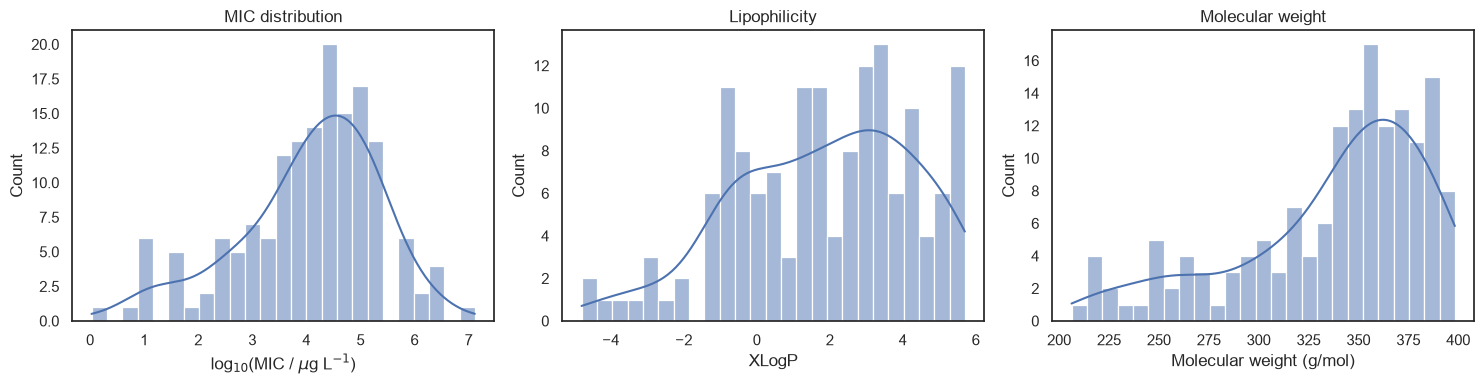

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(
    data=df_molecules,
    x="log_mic",
    bins=25,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("MIC distribution")
axes[0].set_xlabel(r"log$_{10}$(MIC / $\mu$g L$^{-1}$)")

sns.histplot(
    data=df_molecules,
    x="xlogp",
    bins=25,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Lipophilicity")
axes[1].set_xlabel("XLogP")

sns.histplot(
    data=df_molecules,
    x="molecular_weight",
    bins=25,
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Molecular weight")
axes[2].set_xlabel("Molecular weight (g/mol)")

plt.tight_layout()
plt.show()

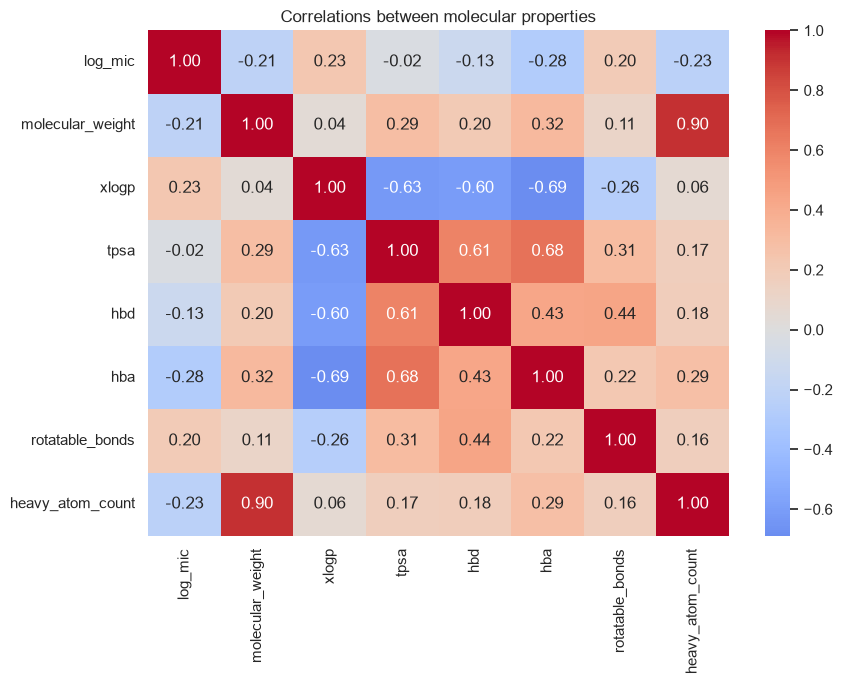

In [14]:
corr_columns = [
    "log_mic",
    "molecular_weight",
    "xlogp",
    "tpsa",
    "hbd",
    "hba",
    "rotatable_bonds",
    "heavy_atom_count"
]

corr = df_molecules[corr_columns].corr()

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax
)

ax.set_title("Correlations between molecular properties")

plt.tight_layout()
plt.show()

## Ten molecules with the lowest MIC

The ten lowest-MIC molecules are drawn with RDKit. Their structures provide a first qualitative comparison, but a low MIC in one assay does not by itself establish that a compound is a suitable antibiotic.

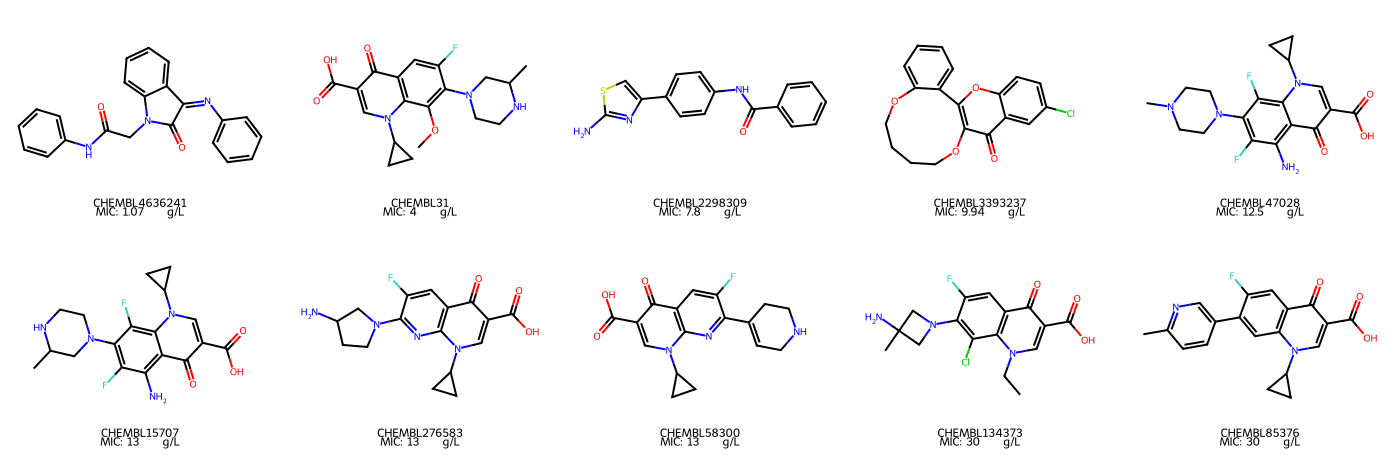

,chembl_id,mic_ug_L,xlogp,molecular_weight
126,CHEMBL4636241,1.0662,3.6,355.40
59,CHEMBL31,4.0000,-0.7,375.40
120,CHEMBL2298309,7.8000,3.1,295.40
145,CHEMBL3393237,9.9412,4.4,342.80
48,CHEMBL47028,12.5000,-0.3,378.40
18,CHEMBL15707,13.0000,-1.3,378.40
112,CHEMBL276583,13.0000,-0.1,332.33
138,CHEMBL58300,13.0000,-0.6,329.32
38,CHEMBL134373,30.0000,-0.9,353.77
86,CHEMBL85376,30.0000,3.6,338.30


In [15]:
from rdkit import Chem
from rdkit.Chem import Draw

# Lowest MIC corresponds to highest antibacterial activity
df_best = df_molecules.nsmallest(10, "mic_ug_L")

molecules = []
legends = []

for row in df_best.itertuples():
    mol = Chem.MolFromSmiles(row.smiles)

    if mol is not None:
        molecules.append(mol)
        legends.append(
            f"{row.chembl_id}\nMIC: {row.mic_ug_L:.3g} µg/L"
        )

if molecules:
    display(
        Draw.MolsToGridImage(
            molecules,
            molsPerRow=5,
            subImgSize=(280, 230),
            legends=legends
        )
    )

display_df(
    best=df_best[
        ["chembl_id", "mic_ug_L", "xlogp", "molecular_weight"]
    ]
)

## XLogP hypothesis

**Working hypothesis:** Molecules with higher XLogP tend to have lower MIC against *E. coli*. The null hypothesis for the t-test is equal mean log(MIC) in the two groups.

The median XLogP is used as the dividing threshold to keep the groups reasonably balanced. As the grouping and hypothesis are explored on the same sample, the test is exploratory.

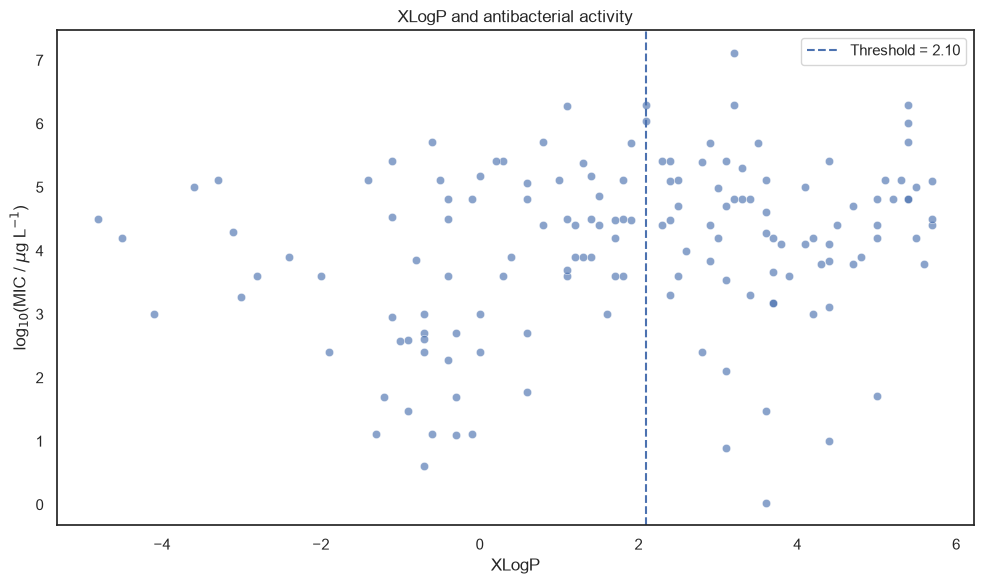

In [16]:
df_analysis = df_molecules.dropna(
    subset=["xlogp", "log_mic"]
).copy()

if df_analysis.empty:
    raise ValueError("No molecules available for XLogP analysis.")

# Initial threshold; can be adjusted after inspecting the plot
threshold = df_analysis["xlogp"].median()

fig, ax = plt.subplots()

sns.scatterplot(
    data=df_analysis,
    x="xlogp",
    y="log_mic",
    alpha=0.65,
    ax=ax
)

ax.axvline(
    threshold,
    linestyle="--",
    label=f"Threshold = {threshold:.2f}"
)

ax.set(
    xlabel="XLogP",
    ylabel=r"log$_{10}$(MIC / $\mu$g L$^{-1}$)",
    title="XLogP and antibacterial activity"
)

ax.legend()
plt.tight_layout()
plt.show()

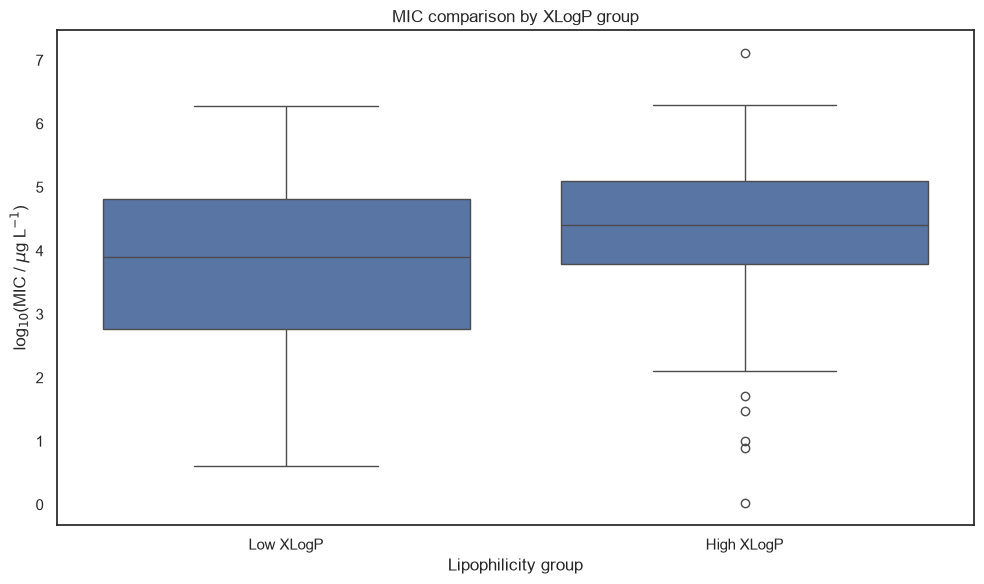

In [17]:
df_analysis["group"] = np.where(
    df_analysis["xlogp"] < threshold,
    "Low XLogP",
    "High XLogP"
)

fig, ax = plt.subplots()

sns.boxplot(
    data=df_analysis,
    x="group",
    y="log_mic",
    order=["Low XLogP", "High XLogP"],
    ax=ax
)

ax.set(
    xlabel="Lipophilicity group",
    ylabel=r"log$_{10}$(MIC / $\mu$g L$^{-1}$)",
    title="MIC comparison by XLogP group"
)

plt.tight_layout()
plt.show()

In [18]:
from scipy.stats import ttest_ind

def run_ttest(data, threshold, label):
    low = data.loc[
        data["xlogp"] < threshold, "log_mic"
    ].dropna()

    high = data.loc[
        data["xlogp"] >= threshold, "log_mic"
    ].dropna()

    result = {
        "Dataset": label,
        "n_low": len(low),
        "n_high": len(high),
        "mean_low": low.mean(),
        "mean_high": high.mean(),
        "t_statistic": np.nan,
        "p_value": np.nan
    }

    if len(low) >= 2 and len(high) >= 2:
        test = ttest_ind(
            low,
            high,
            equal_var=False
        )

        result["t_statistic"] = test.statistic
        result["p_value"] = test.pvalue

    return result


result_all = run_ttest(
    df_analysis,
    threshold,
    "All molecules"
)

display_df(results=pd.DataFrame([result_all]))

,Dataset,n_low,n_high,mean_low,mean_high,t_statistic,p_value
0,All molecules,74,75,3.779054,4.320664,-2.524685,0.012644


### Restricted analysis: MIC below 10 µg/L

The same XLogP threshold is used for the more active subset. If too few molecules remain in either group, the t-test is not interpreted.

Molecules with MIC < 10 µg/L: 4


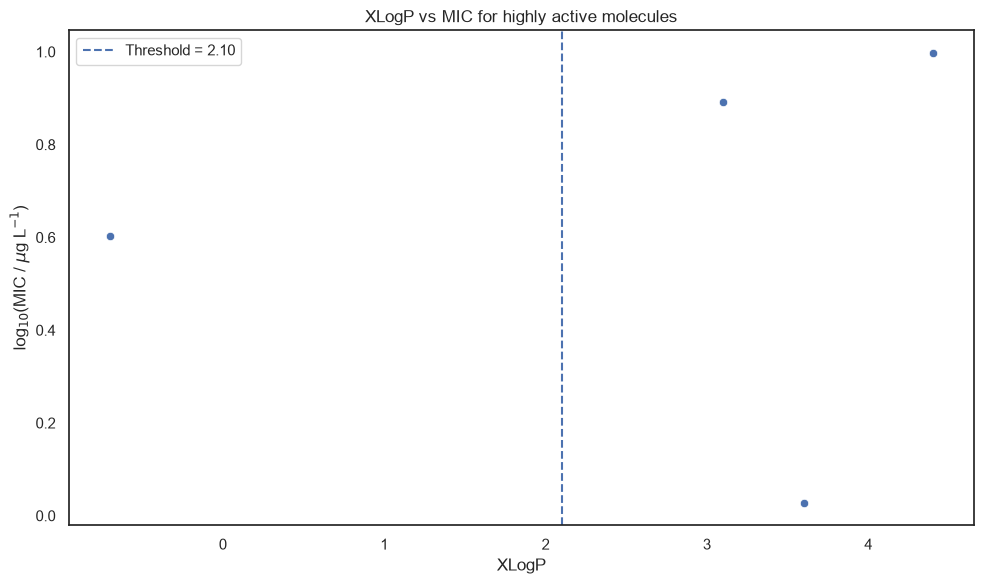

,Dataset,n_low,n_high,mean_low,mean_high,t_statistic,p_value
0,All molecules,74,75,3.779054,4.320664,-2.524685,0.012644
1,MIC < 10 µg/L,1,3,0.602060,0.639124,NaN,NaN


In [19]:
df_active = df_analysis[
    df_analysis["mic_ug_L"] < 10
].copy()

print(f"Molecules with MIC < 10 µg/L: {len(df_active)}")

if not df_active.empty:
    fig, ax = plt.subplots()

    sns.scatterplot(
        data=df_active,
        x="xlogp",
        y="log_mic",
        ax=ax
    )

    ax.axvline(
        threshold,
        linestyle="--",
        label=f"Threshold = {threshold:.2f}"
    )

    ax.set(
        xlabel="XLogP",
        ylabel=r"log$_{10}$(MIC / $\mu$g L$^{-1}$)",
        title="XLogP vs MIC for highly active molecules"
    )

    ax.legend()
    plt.tight_layout()
    plt.show()

result_active = run_ttest(
    df_active,
    threshold,
    "MIC < 10 µg/L"
)

df_results = pd.DataFrame([
    result_all,
    result_active
])

display_df(results=df_results)

In [20]:
for result in [result_all, result_active]:
    print(f"\n{result['Dataset']}")
    print("-" * 40)

    print(f"Low XLogP:  {result['n_low']} molecules")
    print(f"High XLogP: {result['n_high']} molecules")

    if pd.isna(result["p_value"]):
        print("Insufficient data for the t-test.")
        continue

    print(f"p-value: {result['p_value']:.4g}")

    if result["mean_high"] < result["mean_low"]:
        print("Higher XLogP is associated with lower mean MIC.")
    elif result["mean_high"] > result["mean_low"]:
        print("Higher XLogP is associated with higher mean MIC.")
    else:
        print("Both groups have equal mean log(MIC).")

    if result["p_value"] < 0.05:
        print("Statistically significant difference (p < 0.05).")
    else:
        print("No statistically significant difference (p >= 0.05).")


All molecules
----------------------------------------
Low XLogP:  74 molecules
High XLogP: 75 molecules
p-value: 0.01264
Higher XLogP is associated with higher mean MIC.
Statistically significant difference (p < 0.05).

MIC < 10 µg/L
----------------------------------------
Low XLogP:  1 molecules
High XLogP: 3 molecules
Insufficient data for the t-test.


## Discussion and conclusion

In the initial analysis, the higher-XLogP group had **higher**, rather than lower, MIC on average, contrary to the proposed hypothesis. The groups still overlap considerably, so XLogP alone does not give a reliable prediction of antibacterial activity. The group comparison is exploratory and should not be taken as evidence that lipophilicity itself causes the difference.

Several limitations matter here: the 300 records were randomly sampled, MIC values come from different assays, some measurements were excluded because they were censored or could not be converted, and repeated measurements were reduced to one median per molecule. The subset below 10 µg/L is especially small, so no meaningful conclusion can be drawn from its t-test.

For antibiotic development, I would not prioritize candidates solely by XLogP. Molecules with low MIC would be worth examining further, together with other molecular properties and repeat measurements under comparable experimental conditions.